In [1]:
try:
    import google.colab  # noqa: F401

    # specify the version of DataEval (==X.XX.X) for versions other than the latest
    %pip install -q dataeval dataeval-plots maite-datasets
except Exception:
    pass

In [2]:
import dataeval_plots as dep
import numpy as np
import polars as pl
import torch
from IPython.display import display
from maite_datasets.multiobject_tracking import VisDroneMOT
from PIL import Image
from torchvision.models import ResNet18_Weights, resnet18

from dataeval import Embeddings
from dataeval.config import set_device
from dataeval.core import track_path_stats
from dataeval.data import DetectionCrops, Indices, SequenceFrames, View
from dataeval.extractors import TorchExtractor

set_device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
dataset = VisDroneMOT(root="./data", image_set="val", download=True)
frames = SequenceFrames(View(dataset, Indices([3])))
print(f"{frames[0][2]['source_id']}: {len(frames)} frames")

uav0000182_00000_v: 363 frames


In [4]:
crops = DetectionCrops(frames, min_size=16, square="pad")
video, frame = frames.frame_map[crops.item_indices].T
print(f"{len(crops)} crops, {crops.n_dropped} dropped, {len(np.unique(crops.track_ids))} tracks")

17107 crops, 564 dropped, 155 tracks


In [5]:
weights = ResNet18_Weights.DEFAULT
extractor = TorchExtractor(
    resnet18(weights=weights, progress=False), transforms=weights.transforms(), layer_name="avgpool"
)
embeddings = Embeddings(crops, extractor=extractor, batch_size=64)

In [6]:
result = track_path_stats(embeddings, crops.track_ids, frame, video)
paths = pl.DataFrame(result["stats"]).drop_nans().sort("path_displacement", descending=True)
display(paths)

/tmp/ipykernel_6069/2263873864.py:1: ExperimentalWarning: 'track_path_stats' is experimental and may change or be removed in any future release without notice.
  result = track_path_stats(embeddings, crops.track_ids, frame, video)


/tmp/ipykernel_6069/2263873864.py:1: UserWarning: 56 of 155 tracks have fewer than 60 points and are NaN; pass `min_points=` to accept values below the studied range.
  result = track_path_stats(embeddings, crops.track_ids, frame, video)


track_ids,item_index,n_points,path_displacement,path_displacement_null
i64,i64,i64,f64,f64
86,0,317,0.704379,0.067768
70,0,169,0.664552,0.097036
83,0,87,0.655045,0.143977
48,0,141,0.633474,0.097619
31,0,77,0.628377,0.127714
…,…,…,…,…
157,0,143,0.238923,0.07183
107,0,174,0.232532,0.052422
12,0,243,0.227016,0.05898


In [7]:
# TEST ASSERTION CELL ###
assert len(frames) == 363
assert frames[0][2]["source_id"] == "uav0000182_00000_v"
assert (len(crops), crops.n_dropped) == (17107, 564)
assert (crops.track_ids >= 0).all()  # so np.unique counts tracks only
assert len(np.unique(crops.track_ids)) == len(result["stats"]["track_ids"]) == 155
assert paths.height == 99
assert int(np.isnan(result["stats"]["path_displacement"]).sum()) == 56
displacement = paths["path_displacement"].to_numpy()
assert paths["n_points"].to_numpy().min() >= 60
assert abs(displacement.min() - 0.22) < 0.02
assert abs(displacement.max() - 0.70) < 0.02
assert (np.diff(displacement) <= 0).all()  # "farthest first"
assert displacement.max() <= 2.0  # "from 0 to 2"

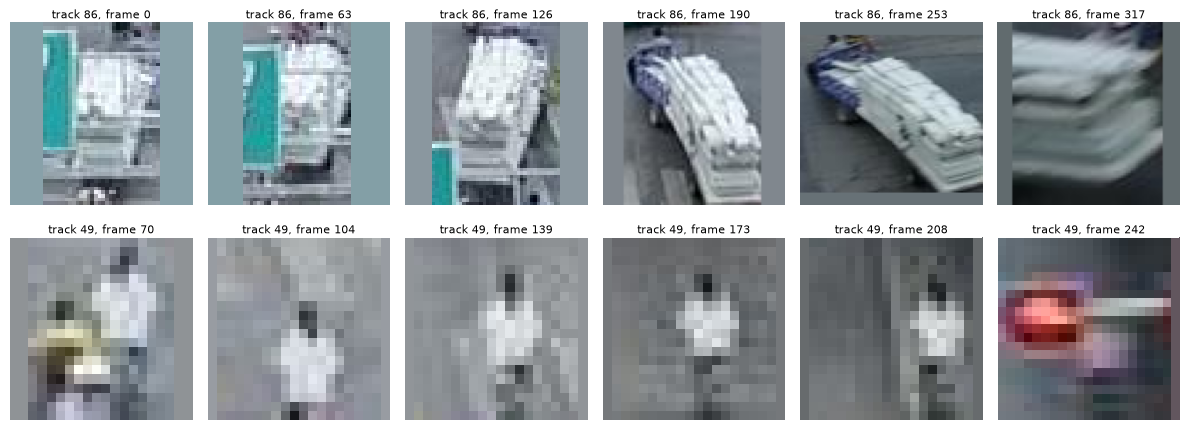

In [8]:
farthest, nearest = paths["track_ids"][0], paths["track_ids"][-1]


def crops_of(track: int, n: int) -> np.ndarray:
    """`n` crop rows of one track, evenly spaced from its first frame to its last."""
    rows = np.flatnonzero(crops.track_ids == track)
    rows = rows[np.argsort(frame[rows])]
    return rows[np.linspace(0, len(rows) - 1, n).round().astype(int)]


shown = np.concatenate([crops_of(farthest, 6), crops_of(nearest, 6)])
dep.plot(
    crops,
    indices=shown.tolist(),
    images_per_row=6,
    titles=[f"track {crops.track_ids[row]}, frame {frame[row]}" for row in shown],
    figsize=(12, 4.6),
)

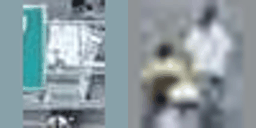

In [9]:
def square(row: int, side: int = 128) -> np.ndarray:
    """One crop, resized to `side` x `side` pixels."""
    return np.asarray(Image.fromarray(np.asarray(crops[int(row)][0]).transpose(1, 2, 0)).resize((side, side)))


pair = [np.hstack([square(a), square(b)]) for a, b in zip(crops_of(farthest, 60), crops_of(nearest, 60), strict=True)]
display(dep.animate(pair, boxes=False, fps=8))

In [10]:
# TEST ASSERTION CELL ###
assert (farthest, nearest) == (86, 49)  # the two tracks the text describes
label_of = {int(crops.track_ids[row]): int(np.argmax(np.asarray(crops[int(row)][1]))) for row in shown}
assert dataset.index2label[label_of[86]] == "tricycle"
assert dataset.index2label[label_of[49]] == "motor"
assert [frame[row] for row in crops_of(farthest, 6)] == [0, 63, 126, 190, 253, 317]
assert len(pair) == 60
assert pair[0].shape == (128, 256, 3)